# Лабораторная работа № 6
## Решение задачи кластеризации
**Цель работы**: научиться производить кластерный анализ данных с использованием метода К-средних.

Проанализируем датасет hate_crimes. Набор данных содержит данные, лежащие в основе статьи «Более высокие показатели преступлений на почве ненависти связаны с неравенством доходов».

**Признаки**:
* State – штат
* median_household_income – средний доход домохозяйства, 2016 г.
* share_unemployed_seasonal – доля безработного населения (с поправкой на сезонность), сентябрь 2016 г.
* share_population_in_metro_areas – доля населения, проживающего в мегаполисах, 2015 г.
* share_population_with_high_school_degree – доля взрослых в возрасте 25 лет и старше, имеющих диплом об окончании средней школы, 2009 г.
* share_non_citizen – доля населения, не являющегося гражданами США 2015 г.
* share_white_poverty – доля белых жителей, живущих в бедности, 2015 г.
* gini_index – индекс Джини, 2015 г.
* share_non_white – доля населения, не являющегося белым, 2015 г.
* share_voters_voted_trump – доля избирателей, проголосовавших за Дональда Трампа на выборах президента США в 2016 году
* hate_crimes_per_100k_splc – преступления на почве ненависти на 100 000 населения, Southern Poverty Law Center, 9–18 ноября 2016 г.
* avg_hatecrimes_per_100k_fbi – среднегодовое количество преступлений на почве ненависти на 100 000 человек населения, ФБР, 2010-2015 гг.

### Импорт необходимых библиотек и загрузка датасета

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from IPython.display import display

df = pd.read_csv('hate_crimes.csv', skipinitialspace=True)
df.head()

,state,median_household_income,share_unemployed_seasonal,share_population_in_metro_areas,share_population_with_high_school_degree,share_non_citizen,share_white_poverty,gini_index,share_non_white,share_voters_voted_trump,hate_crimes_per_100k_splc,avg_hatecrimes_per_100k_fbi
0,Alabama,42278,0.060,0.64,0.821,0.02,0.12,0.472,0.35,0.63,0.125839,1.806410
1,Alaska,67629,0.064,0.63,0.914,0.04,0.06,0.422,0.42,0.53,0.143740,1.656700
2,Arizona,49254,0.063,0.90,0.842,0.10,0.09,0.455,0.49,0.50,0.225320,3.413928
3,Arkansas,44922,0.052,0.69,0.824,0.04,0.12,0.458,0.26,0.60,0.069061,0.869209
4,California,60487,0.059,0.97,0.806,0.13,0.09,0.471,0.61,0.33,0.255805,2.397986


### Получение информации о датасете

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 12 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   state                                     51 non-null     str    
 1   median_household_income                   51 non-null     int64  
 2   share_unemployed_seasonal                 51 non-null     float64
 3   share_population_in_metro_areas           51 non-null     float64
 4   share_population_with_high_school_degree  51 non-null     float64
 5   share_non_citizen                         48 non-null     float64
 6   share_white_poverty                       51 non-null     float64
 7   gini_index                                51 non-null     float64
 8   share_non_white                           51 non-null     float64
 9   share_voters_voted_trump                  51 non-null     float64
 10  hate_crimes_per_100k_splc                 47 non-nu

### Исключение невлияющего категориального признака

In [3]:
states = df['state']
df.drop('state', axis='columns', inplace=True)
df.head()

,median_household_income,share_unemployed_seasonal,share_population_in_metro_areas,share_population_with_high_school_degree,share_non_citizen,share_white_poverty,gini_index,share_non_white,share_voters_voted_trump,hate_crimes_per_100k_splc,avg_hatecrimes_per_100k_fbi
0,42278,0.060,0.64,0.821,0.02,0.12,0.472,0.35,0.63,0.125839,1.806410
1,67629,0.064,0.63,0.914,0.04,0.06,0.422,0.42,0.53,0.143740,1.656700
2,49254,0.063,0.90,0.842,0.10,0.09,0.455,0.49,0.50,0.225320,3.413928
3,44922,0.052,0.69,0.824,0.04,0.12,0.458,0.26,0.60,0.069061,0.869209
4,60487,0.059,0.97,0.806,0.13,0.09,0.471,0.61,0.33,0.255805,2.397986


### Проверка на наличие пропущенных значений

In [4]:
df.isna().sum()

median_household_income                     0
share_unemployed_seasonal                   0
share_population_in_metro_areas             0
share_population_with_high_school_degree    0
share_non_citizen                           3
share_white_poverty                         0
gini_index                                  0
share_non_white                             0
share_voters_voted_trump                    0
hate_crimes_per_100k_splc                   4
avg_hatecrimes_per_100k_fbi                 1
dtype: int64

### Заполнение пропущенных значений средними значениями признаков

In [5]:
for key in df.keys():
  if df[key].hasnans:
    mean = df[key].mean()
    print(f'Заполняется признак {key} средним значением: {mean}')

    df[key] = df[key].fillna(mean)

df.isna().sum()

Заполняется признак share_non_citizen средним значением: 0.054583333333333324
Заполняется признак hate_crimes_per_100k_splc средним значением: 0.30409296995744683
Заполняется признак avg_hatecrimes_per_100k_fbi средним значением: 2.36761300684


median_household_income                     0
share_unemployed_seasonal                   0
share_population_in_metro_areas             0
share_population_with_high_school_degree    0
share_non_citizen                           0
share_white_poverty                         0
gini_index                                  0
share_non_white                             0
share_voters_voted_trump                    0
hate_crimes_per_100k_splc                   0
avg_hatecrimes_per_100k_fbi                 0
dtype: int64

### Приведение данных к единому масштабу

In [6]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [7]:
x = scaler.fit_transform(df)
print(x[:4, :])

[[-1.41982451  0.98476651 -0.61288736 -1.4262347  -1.15921468  1.1538106
   0.88157401  0.21013931  1.19108239 -0.74272062 -0.33399024]
 [ 1.36057573  1.36238375 -0.66850526  1.33033872 -0.48882547 -1.29803692
  -1.53564506  0.6388235   0.34030925 -0.66813278 -0.42308785]
 [-0.65472364  1.26797944  0.83317784 -0.80378264  1.52234218 -0.07211316
   0.05971953  1.06750769  0.08507731 -0.32821889  0.62269677]
 [-1.12984076  0.22953204 -0.3347979  -1.33731298 -0.48882547  1.1538106
   0.20475267 -0.34102608  0.93585045 -0.97929481 -0.89175002]]


### Использование метода локтя

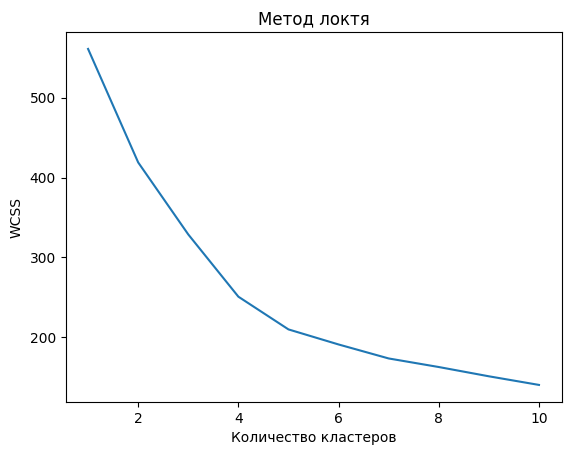

In [8]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
  kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
  kmeans.fit(x)
  wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss)
plt.title('Метод локтя')
plt.xlabel('Количество кластеров')
plt.ylabel('WCSS')
plt.show()

На графике можно заметить, что наибольший перегиб находится на значении 5

Следовательно, оптимальное количество кластеров должно быть 5

### Обучение модели кластеризации

In [9]:
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, init='k-means++', random_state=42)
kmeans.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


### Предсказание кластеров

In [10]:
clusters = kmeans.predict(x)
df['cluster'] = clusters
df.head()

,median_household_income,share_unemployed_seasonal,share_population_in_metro_areas,share_population_with_high_school_degree,share_non_citizen,share_white_poverty,gini_index,share_non_white,share_voters_voted_trump,hate_crimes_per_100k_splc,avg_hatecrimes_per_100k_fbi,cluster
0,42278,0.060,0.64,0.821,0.02,0.12,0.472,0.35,0.63,0.125839,1.806410,1
1,67629,0.064,0.63,0.914,0.04,0.06,0.422,0.42,0.53,0.143740,1.656700,0
2,49254,0.063,0.90,0.842,0.10,0.09,0.455,0.49,0.50,0.225320,3.413928,1
3,44922,0.052,0.69,0.824,0.04,0.12,0.458,0.26,0.60,0.069061,0.869209,1
4,60487,0.059,0.97,0.806,0.13,0.09,0.471,0.61,0.33,0.255805,2.397986,4


### Визуализация кластеров

Т.к. признаков очень много - будет использоваться метод PCA

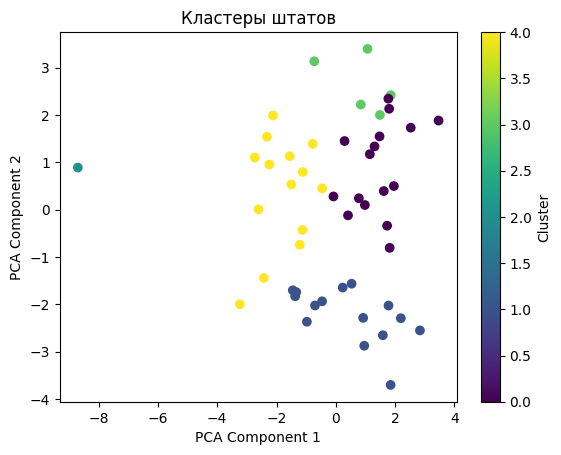

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x)

plt.scatter(x_pca[:, 0], x_pca[:, 1], c=clusters, cmap='viridis')
plt.title('Кластеры штатов')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(label='Cluster')
plt.show()

### Группировка по кластерам

In [12]:
df.groupby('cluster').mean()

,median_household_income,share_unemployed_seasonal,share_population_in_metro_areas,share_population_with_high_school_degree,share_non_citizen,share_white_poverty,gini_index,share_non_white,share_voters_voted_trump,hate_crimes_per_100k_splc,avg_hatecrimes_per_100k_fbi
cluster,,,,,,,,,,,
0,54460.937500,0.044687,0.622500,0.89175,0.032448,0.095000,0.440688,0.200625,0.540000,0.283868,1.878029
1,45218.600000,0.058533,0.748667,0.82840,0.055639,0.112000,0.464067,0.387333,0.551333,0.190822,1.766500
2,68277.000000,0.067000,1.000000,0.87100,0.110000,0.040000,0.532000,0.630000,0.040000,1.522302,10.953480
3,64324.800000,0.033000,0.660000,0.90620,0.040000,0.070000,0.429800,0.164000,0.526000,0.275832,3.105957
4,62632.071429,0.050214,0.912143,0.87350,0.080000,0.077857,0.460643,0.402143,0.386429,0.371648,2.694217


In [13]:
# Возвращение категориального признака
df['state'] = states
df.head()

,median_household_income,share_unemployed_seasonal,share_population_in_metro_areas,share_population_with_high_school_degree,share_non_citizen,share_white_poverty,gini_index,share_non_white,share_voters_voted_trump,hate_crimes_per_100k_splc,avg_hatecrimes_per_100k_fbi,cluster,state
0,42278,0.060,0.64,0.821,0.02,0.12,0.472,0.35,0.63,0.125839,1.806410,1,Alabama
1,67629,0.064,0.63,0.914,0.04,0.06,0.422,0.42,0.53,0.143740,1.656700,0,Alaska
2,49254,0.063,0.90,0.842,0.10,0.09,0.455,0.49,0.50,0.225320,3.413928,1,Arizona
3,44922,0.052,0.69,0.824,0.04,0.12,0.458,0.26,0.60,0.069061,0.869209,1,Arkansas
4,60487,0.059,0.97,0.806,0.13,0.09,0.471,0.61,0.33,0.255805,2.397986,4,California


In [14]:
# Отображение штатов кластеров
for cluster_num in range(n_clusters):
  print(f"Штаты {cluster_num} кластера:")
  print(df[df['cluster'] == cluster_num]['state'].values)

Штаты 0 кластера:
<StringArray>
[      'Alaska',        'Idaho',      'Indiana',         'Iowa',
       'Kansas',        'Maine',     'Michigan',     'Missouri',
      'Montana',         'Ohio',     'Oklahoma', 'Pennsylvania',
 'South Dakota',      'Vermont',    'Wisconsin',      'Wyoming']
Length: 16, dtype: str
Штаты 1 кластера:
<StringArray>
[       'Alabama',        'Arizona',       'Arkansas',        'Florida',
        'Georgia',       'Kentucky',      'Louisiana',    'Mississippi',
         'Nevada',     'New Mexico', 'North Carolina', 'South Carolina',
      'Tennessee',          'Texas',  'West Virginia']
Length: 15, dtype: str
Штаты 2 кластера:
<StringArray>
['District of Columbia']
Length: 1, dtype: str
Штаты 3 кластера:
<StringArray>
['Minnesota', 'Nebraska', 'New Hampshire', 'North Dakota', 'Utah']
Length: 5, dtype: str
Штаты 4 кластера:
<StringArray>
[   'California',      'Colorado',   'Connecticut',      'Delaware',
        'Hawaii',      'Illinois',      'Maryland', 'Ma

Интерпретация:
- Кластер 0 — Штаты с низким уровнем преступности на почве ненависти, высоким доходом и высоким процентом голосов за Трампа
- Кластер 1 — Штаты с низким уровнем преступности на почве ненависти, низким доходом и низким уровнем образования
- Кластер 2 — District of Columbia: аномально высокий уровень преступности на почве ненависти, максимальное неравенство, почти нулевая поддержка Трампа
- Кластер 3 — Штаты с высоким уровнем преступности на почве ненависти, высоким доходом и высоким процентом голосов за Трампа
- Кластер 4 — Штаты с высоким уровнем преступности на почве ненависти, высоким доходом и низким процентом голосов за Трампа